<a href="https://colab.research.google.com/github/mkobycheva/air-raid-alert-analysis/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import pandas as pd

In [24]:
df = pd.read_csv('official_data_en.csv', parse_dates=['started_at','finished_at']).drop_duplicates()
print('min:', df.started_at.min()); print('max:', df.started_at.max())
print(df.level.value_counts()); print(df.source.value_counts())
print(df.oblast.nunique(), 'областей')
print(df.set_index('started_at').resample('MS').size().tail(8))

min: 2022-03-15 16:10:34+00:00
max: 2026-09-07 05:28:22+00:00
level
raion      99304
oblast     65314
hromada    20812
Name: count, dtype: int64
source
official    185430
Name: count, dtype: int64
25 областей
started_at
2026-02-01 00:00:00+00:00     7922
2026-03-01 00:00:00+00:00     9788
2026-04-01 00:00:00+00:00     8609
2026-05-01 00:00:00+00:00    10065
2026-06-01 00:00:00+00:00    10006
2026-07-01 00:00:00+00:00    11073
2026-08-01 00:00:00+00:00    10636
2026-09-01 00:00:00+00:00     1937
Freq: MS, dtype: int64


In [25]:
lvl = (df.assign(m=df.started_at.dt.to_period("M"))
         .groupby(["m","level"]).size().unstack(fill_value=0))
print(lvl.div(lvl.sum(axis=1), axis=0).round(2).to_string())

level    hromada  oblast  raion
m                              
2022-03     0.25    0.60   0.15
2022-04     0.16    0.71   0.13
2022-05     0.17    0.77   0.06
2022-06     0.20    0.75   0.05
2022-07     0.21    0.77   0.03
2022-08     0.18    0.81   0.01
2022-09     0.17    0.81   0.01
2022-10     0.13    0.87   0.00
2022-11     0.11    0.89   0.00
2022-12     0.08    0.92   0.00
2023-01     0.08    0.92   0.00
2023-02     0.07    0.93   0.00
2023-03     0.05    0.95   0.00
2023-04     0.08    0.92   0.00
2023-05     0.06    0.94   0.00
2023-06     0.04    0.96   0.00
2023-07     0.04    0.96   0.00
2023-08     0.04    0.95   0.00
2023-09     0.05    0.95   0.00
2023-10     0.08    0.92   0.00
2023-11     0.10    0.90   0.00
2023-12     0.09    0.91   0.00
2024-01     0.10    0.90   0.00
2024-02     0.22    0.78   0.00
2024-03     0.20    0.80   0.00
2024-04     0.21    0.79   0.00
2024-05     0.20    0.80   0.00
2024-06     0.19    0.81   0.00
2024-07     0.16    0.84   0.00
2024-08 

/tmp/ipykernel_2866/1549618783.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  lvl = (df.assign(m=df.started_at.dt.to_period("M"))


## Plots

off 185430 | NaT: 0 | негатив: 0 | >24год: 897
vol 115793 | NaT: 0 | негатив: 0 | >24год: 14
назви, що не збігаються: set()
started_at
2025-11    0.052275
2025-12    0.048295
2026-01    0.047893
2026-02    0.044957
2026-03    0.033134
2026-04    0.037321
2026-05    0.041495
2026-06    0.035444
2026-07    0.046935
2026-08    0.044944
2026-09    0.063091
2026-10    0.091429
Freq: M, Name: naive, dtype: float64


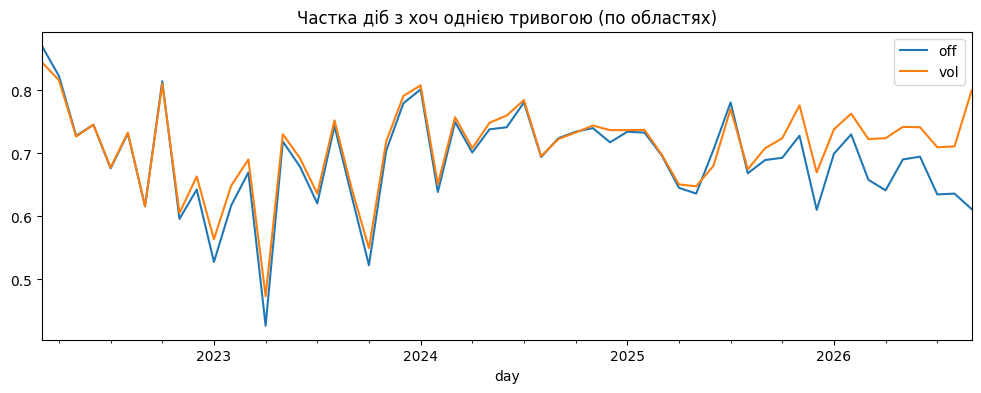

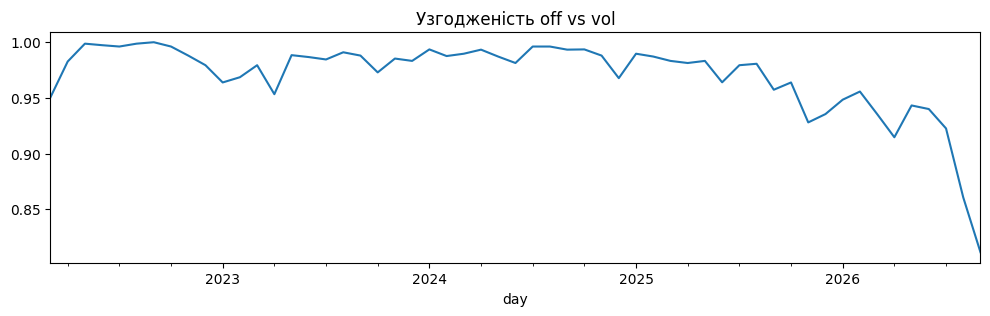

In [26]:
import pandas as pd, matplotlib.pyplot as plt
TZ = "Europe/Kyiv"
off = pd.read_csv("official_data_en.csv", parse_dates=["started_at","finished_at"]).drop_duplicates()
vol = pd.read_csv("volunteer_data_en.csv", parse_dates=["started_at","finished_at"])

# базові перевірки
for n, d in [("off", off), ("vol", vol)]:
    dur = (d.finished_at - d.started_at).dt.total_seconds()/3600
    print(n, len(d), "| NaT:", d.finished_at.isna().sum(),
          "| негатив:", (dur<0).sum(), "| >24год:", (dur>24).sum())
print("назви, що не збігаються:", set(off.oblast.dropna()) ^ set(vol.region))
print(vol.groupby(vol.started_at.dt.tz_convert(None).dt.to_period("M")).naive.mean().tail(12))

def daily_panel(df, col):
    s = df[[col,"started_at","finished_at"]].dropna().copy()
    f = lambda x: x.dt.tz_convert(TZ).dt.tz_localize(None).dt.normalize()
    s["d0"], s["d1"] = f(s.started_at), f(s.finished_at)
    s["n"] = (s.d1 - s.d0).dt.days
    s = s[s.n >= 0]
    s = s.loc[s.index.repeat(s.n + 1)]
    s["day"] = s.d0 + pd.to_timedelta(s.groupby(level=0).cumcount(), unit="D")
    return s.drop_duplicates([col,"day"])[[col,"day"]].assign(alert=1)

po = daily_panel(off, "oblast")
pv = daily_panel(vol, "region").rename(columns={"region":"oblast"})
days = pd.date_range("2022-03-15", "2026-09-07")
regs = sorted(set(po.oblast) & set(pv.oblast))
idx = pd.MultiIndex.from_product([days, regs], names=["day","oblast"])
grid = lambda p: p.set_index(["day","oblast"]).alert.reindex(idx, fill_value=0)
g = pd.DataFrame({"off": grid(po), "vol": grid(pv)})
mon = g.groupby(g.index.get_level_values("day").to_period("M"))

# графік 1: частка діб з тривогою, два джерела
mon[["off","vol"]].mean().plot(figsize=(12,4), title="Частка діб з хоч однією тривогою (по областях)")
plt.show()
# графік 2: узгодженість джерел по місяцях
(mon.apply(lambda x: (x.off == x.vol).mean())).plot(figsize=(12,3), title="Узгодженість off vs vol")
plt.show()

## Differences

In [27]:
d = g.reset_index()
rec = d[d.day >= "2026-01-01"].copy()
print(pd.crosstab(rec.off, rec.vol))       # матриця 2x2 збігів/розбіжностей
rec["vo"] = (rec.vol==1) & (rec.off==0)    # vol бачить, official ні
rec["ov"] = (rec.off==1) & (rec.vol==0)    # навпаки
gap = rec.groupby("oblast")[["vo","ov"]].sum().sort_values("vo", ascending=False)
print(gap)

# приклад: сирі рядки для однієї розбіжної доби
o = gap.index[0]
day = rec[(rec.oblast==o) & rec.vo].day.iloc[0]
loc = lambda s: s.dt.tz_convert("Europe/Kyiv").dt.normalize().dt.tz_localize(None)
print(o, day)
print(vol[(vol.region==o) & (loc(vol.started_at)==day)])
print(off[(off.oblast==o) & (loc(off.started_at)==day)])

vol     0     1
off            
0    1626   432
1      43  4149
                          vo  ov
oblast                          
Lvivska oblast           163   0
Volynska oblast          160   0
Kyiv City                 26   0
Khersonska oblast         12   0
Khmelnytska oblast        11   3
Ternopilska oblast         8   4
Chernivetska oblast        8   3
Vinnytska oblast           5  12
Rivnenska oblast           5   3
Mykolaivska oblast         5   0
Odeska oblast              5   0
Zhytomyrska oblast         4   4
Zakarpatska oblast         4   2
Kyivska oblast             4   3
Cherkaska oblast           4   4
Ivano-Frankivska oblast    3   1
Poltavska oblast           3   0
Kirovohradska oblast       1   1
Chernihivska oblast        1   1
Dnipropetrovska oblast     0   0
Donetska oblast            0   1
Kharkivska oblast          0   0
Luhanska oblast            0   0
Sumska oblast              0   0
Zaporizka oblast           0   1
Lvivska oblast 2026-01-01 00:00:00
          

In [28]:
print(off[(off.finished_at-off.started_at) > pd.Timedelta("24h")].oblast.value_counts())

oblast
Donetska oblast           392
Dnipropetrovska oblast    386
Zaporizka oblast           67
Kharkivska oblast          18
Sumska oblast              12
Chernihivska oblast        12
Kyivska oblast              4
Kirovohradska oblast        3
Zakarpatska oblast          2
Luhanska oblast             1
Name: count, dtype: int64


## Investigating Lviv/Volyn differences between datasets

In [29]:
# 1) Коли саме official пропускає Львів/Волинь
rec["month"] = rec.day.dt.to_period("M")
print(rec[rec.oblast.isin(["Lvivska oblast","Volynska oblast"])]
      .groupby(["month","oblast"]).vo.sum().unstack())
o26 = off[off.started_at >= "2026-01-01"]
print(o26[o26.oblast.isin(["Lvivska oblast","Volynska oblast"])]
      .groupby(["oblast","level"]).size())

# 2) Що за довгі записи на Дніпропетровщині
dur = off.finished_at - off.started_at
print(off[(dur > pd.Timedelta("24h")) & (off.oblast=="Dnipropetrovska oblast")]
      [["raion","hromada","level","started_at","finished_at"]].head(8))

# 3) Базова частка діб з тривогою по областях (2026)
print(rec.groupby("oblast")[["off","vol"]].mean().round(2))

oblast   Lvivska oblast  Volynska oblast
month                                   
2026-01              17               15
2026-02              12               12
2026-03              19               23
2026-04              17               21
2026-05              14               18
2026-06              20               17
2026-07              29               25
2026-08              28               25
2026-09               7                4
oblast           level
Lvivska oblast   raion    501
Volynska oblast  raion    353
dtype: int64
                   raion                                           hromada  \
43051  Nikopolskyi raion                     Myrivska terytorialna hromada   
43279  Nikopolskyi raion  m. Marhanets ta Marhanetska terytorialna hromada   
43280  Nikopolskyi raion                     Myrivska terytorialna hromada   
45142  Nikopolskyi raion          Chervonohryhorivska terytorialna hromada   
45401  Nikopolskyi raion                     Myrivska terytoria

## Comparing volunteer to official data (242 год 40 хв. alerts in Kyiv in September)

In [30]:
def union_hours(df, col, name, start, end):
    s = df.loc[df[col]==name, ["started_at","finished_at"]].sort_values("started_at")
    total, cs, ce = pd.Timedelta(0), None, None
    for a, b in zip(s.started_at.clip(lower=start), s.finished_at.clip(upper=end)):
        if b <= a: continue
        if ce is None or a > ce:
            if ce is not None: total += ce - cs
            cs, ce = a, b
        else:
            ce = max(ce, b)
    if ce is not None: total += ce - cs
    return total.total_seconds() / 3600

start = pd.Timestamp("2026-08-31 21:00", tz="UTC")   # 1 вересня 00:00 за Києвом
end   = pd.Timestamp("2026-09-30 21:00", tz="UTC")   # 1 жовтня 00:00
print(union_hours(vol, "region", "Kyiv City", start, end), "год (еталон ~242.7)")

70.91055555555556 год (еталон ~242.7)


## Some additional checks:
- Percentage of hours with alerts by region
- Kyiv hours comparison
- Lviv official check

In [31]:
def hourly(df, col, start, end):
    s = df[[col,"started_at","finished_at"]].dropna()
    s = s[(s.finished_at >= start) & (s.started_at < end)].copy()
    s["h0"] = s.started_at.dt.floor("h"); s["h1"] = s.finished_at.dt.floor("h")
    s["n"] = ((s.h1 - s.h0) / pd.Timedelta("1h")).astype(int)
    s = s.loc[s.index.repeat(s.n + 1)]
    s["hour"] = s.h0 + pd.to_timedelta(s.groupby(level=0).cumcount(), unit="h")
    return s.drop_duplicates([col,"hour"])[[col,"hour"]]

# 1) частка ГОДИН під тривогою по областях, 2026
st, en = pd.Timestamp("2026-01-01", tz="UTC"), pd.Timestamp("2026-09-07", tz="UTC")
H = (en - st) / pd.Timedelta("1h")
for name, d, c in [("off", off, "oblast"), ("vol", vol, "region")]:
    h = hourly(d, c, st, en); h = h[(h.hour >= st) & (h.hour < en)]
    print(name); print((h.groupby(c).size() / H).round(2).sort_values().to_string())

# 2) Київ, серпень: чи збігаються джерела в годинах (union_hours з попереднього коду)
s8, e8 = pd.Timestamp("2026-07-31 21:00", tz="UTC"), pd.Timestamp("2026-08-31 21:00", tz="UTC")
print("Київ, серпень | off:", union_hours(off,"oblast","Kyiv City",s8,e8),
      "| vol:", union_hours(vol,"region","Kyiv City",s8,e8))

# 3) Львів: що official показує в інших областях під час тривог volunteer
lv = vol[(vol.region=="Lvivska oblast") & (vol.started_at >= "2026-01-01") & (vol.started_at < "2026-01-08")]
for _, r in lv.head(6).iterrows():
    near = off[(off.started_at <= r.finished_at) & (off.finished_at >= r.started_at)]
    print(r.started_at, "→", near.oblast.value_counts().to_dict())

off
oblast
Ivano-Frankivska oblast    0.02
Lvivska oblast             0.02
Zakarpatska oblast         0.02
Chernivetska oblast        0.03
Ternopilska oblast         0.03
Volynska oblast            0.04
Khmelnytska oblast         0.05
Rivnenska oblast           0.07
Vinnytska oblast           0.09
Kyiv City                  0.14
Zhytomyrska oblast         0.16
Cherkaska oblast           0.23
Kirovohradska oblast       0.32
Kyivska oblast             0.32
Odeska oblast              0.38
Mykolaivska oblast         0.45
Khersonska oblast          0.46
Poltavska oblast           0.52
Chernihivska oblast        0.82
Sumska oblast              0.93
Zaporizka oblast           0.93
Kharkivska oblast          0.96
Donetska oblast            0.98
Dnipropetrovska oblast     1.00
vol
region
Ivano-Frankivska oblast    0.02
Zakarpatska oblast         0.04
Rivnenska oblast           0.05
Chernivetska oblast        0.06
Ternopilska oblast         0.06
Vinnytska oblast           0.07
Khmelnytska oblast

# TRAIN-only STL / panel EDA (Task 5B)

The cells above are preserved historical exploratory EDA and are not re-executed here. Earlier exploration overlapped the reserved TEST window; it is not model-selection evidence. The TRAIN-only section below follows.


# TRAIN-only descriptive EDA

Official variant B; no TEST rows or target hours. STL is two-sided and descriptive only. No decomposition component is a model feature. National exposure is the **sum** of per-region exact union hours, including Kyiv City as a separate target. Recompute from the repo root with `PYTHONPATH=src python3 scripts/run_eda.py`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
root = Path.cwd() if Path("src/airalerts").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))
from airalerts.eda import prepare_eda, decompose
out = root / "reports/eda"
daily, chosen = prepare_eda(root / "data/processed/panel.csv.gz", root / "data/raw/official_data_en.csv", out)
strengths = decompose(daily, chosen, out)


/Users/masha/air-raid-alert-analisys/src/airalerts/io.py:12: UserWarning: 897 intervals longer than 24 h (retained)
  validate(df)


## Panel and TRAIN base rates

Flags use TRAIN hourly y_0 rates below 3% or above 95%, independently for each fold. First-fold TRAIN also chooses the representative regions: highest eastern rate, central rate nearest the overall median, lowest western rate; lexical ties. The common embargo is 25 hours.


In [2]:
print(pd.read_csv(out / "panel_overview.csv").to_string(index=False))
rates = pd.read_csv(out / "train_base_rates.csv")
print(rates.to_string(index=False))
print("Representatives selected on first-fold TRAIN:")
print(chosen.to_string(index=False))


  rows  oblasts                     min_T                     max_T  embargo_hours
139968       24 2025-12-01 00:00:00+00:00 2026-07-31 23:00:00+00:00             25
                 oblast  base_rate    n  flagged  fold_id       train_end_exclusive
       Cherkaska oblast   0.220355 4343    False        1 2026-05-30T23:00:00+00:00
    Chernihivska oblast   0.762837 4343    False        1 2026-05-30T23:00:00+00:00
    Chernivetska oblast   0.038453 4343    False        1 2026-05-30T23:00:00+00:00
 Dnipropetrovska oblast   0.954179 4343     True        1 2026-05-30T23:00:00+00:00
        Donetska oblast   0.945890 4343    False        1 2026-05-30T23:00:00+00:00
Ivano-Frankivska oblast   0.032466 4343    False        1 2026-05-30T23:00:00+00:00
      Kharkivska oblast   0.901681 4343    False        1 2026-05-30T23:00:00+00:00
      Khersonska oblast   0.446466 4343    False        1 2026-05-30T23:00:00+00:00
     Khmelnytska oblast   0.058485 4343    False        1 2026-05-30T23:00:00+

## Weekly STL

Robust STL, period 7 days, seasonal smoother 13. F = max(0, 1 − Var(remainder)/Var(component+remainder)); a zero denominator is undefined. Only complete Kyiv calendar days contained in first-fold TRAIN are used, accounting for the 23-hour DST day.


In [3]:
print(strengths.to_string(index=False))
print((out / "stl_description.md").read_text())


                series  n_days  period_days      F_T      F_S
              NATIONAL     180            7 0.145250 0.000000
Dnipropetrovska oblast     180            7 0.074584 0.000000
  Kirovohradska oblast     180            7 0.153392 0.076482
    Zakarpatska oblast     180            7 0.010876 0.045652
Descriptive, two-sided STL on 180 complete TRAIN days gives NATIONAL F_T=0.1453 and F_S=0.0000.

The trend component has the larger NATIONAL variance-reduction strength under this decomposition; this is not forecast skill.

The east/center/west representatives were chosen from first-fold TRAIN rates: highest east, center nearest the overall median, and lowest west; their individual strengths are in stl_strength.csv.

STL uses observations on both sides of each date, so its components never enter model features; the supplied December 2025 definition break also limits causal interpretation.

The ACF is for daily national exposure: its lag is in days and is not the hourly forecast lea

![Descriptive STL for NATIONAL](../reports/eda/stl_NATIONAL.png)


![Descriptive STL for Dnipropetrovska_oblast](../reports/eda/stl_Dnipropetrovska_oblast.png)


![Descriptive STL for Kirovohradska_oblast](../reports/eda/stl_Kirovohradska_oblast.png)


![Descriptive STL for Zakarpatska_oblast](../reports/eda/stl_Zakarpatska_oblast.png)


## ACF

ACF lag is measured in **days**, not the forecast lead k (hours). It describes dependence, not forecast validation skill.

![Daily national ACF](../reports/eda/national_acf.png)

Figures are regenerated by the CLI above. Rendering requires matplotlib; computation requires statsmodels. No calendar features or predictive models are added here.
